# 16. Write a python program to perform frequency domain filtering using Ideal, Butterworth, and Gaussian low-pass/high-pass filters.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)

In [3]:
height, width = img.shape

In [5]:
f = np.fft.fft2(img)
f_shift = np.fft.fftshift(f)
f_shift

array([[  18.28141998-242.18030233j,  -56.05439939+306.03005405j,
        -239.41240045-244.49904662j, ..., -239.41240045+244.49904662j,
         -56.05439939-306.03005405j,   18.28141998+242.18030233j],
       [ 260.13113201+236.99898233j, -185.00234854 -65.74842063j,
         128.20439816 -83.70692817j, ...,   79.22723047-437.38642454j,
         271.81711649+302.79805023j, -230.69814136-251.94673317j],
       [-571.4181268 +370.13717686j,  219.74397137-398.67601491j,
         -11.73006522+553.34819766j, ...,   99.97445289+158.93117513j,
        -494.5299593  -91.69771867j,  721.07586302-155.93975025j],
       ...,
       [-828.88153648  -7.76675234j,  803.47087167 +26.72470103j,
        -431.37573128-129.0410071j , ..., -340.55749411+298.79464475j,
          95.04329412-331.48601623j,  554.29032452+250.69784568j],
       [ 721.07586302+155.93975025j, -494.5299593  +91.69771867j,
          99.97445289-158.93117513j, ...,  -11.73006522-553.34819766j,
         219.74397137+398.67601491j

In [7]:
# Create distance matrix
crow, ccol = height // 2, width // 2
crow, ccol

(74, 82)

In [8]:
D = np.zeros(img.shape)

In [9]:
for i in range(height):
    for j in range(width):
        D[i, j] = np.sqrt((i-crow)**2 + (j-ccol)**2)

In [10]:
# Parameters
D0 = 30
n = 2

In [11]:
# Create filter masks
ILPF = np.zeros(img.shape)
IHPF = np.zeros(img.shape)
BLPF = np.zeros(img.shape)
BHPF = np.zeros(img.shape)
GLPF = np.zeros(img.shape)
GHPF = np.zeros(img.shape)

In [12]:
for i in range(height):
    for j in range(width):
        d = D[i, j]

        # Ideal Filter
        if d <= D0:
            ILPF[i, j] = 1
            IHPF[i, j] = 0
        else:
            ILPF[i, j] = 0
            IHPF[i, j] = 1

        # Butterworth Filter
        BLPF[i, j] = 1 / (1 + (d / D0)**(2*n))

        if d == 0:
            BHPF[i, j] = 0
        else:
            BHPF[i, j] = 1 / (1 + (D0 / d)**(2*n))
            
        # Gaussian Filter
        GLPF[i, j] = np.exp(-(d**2) / (2 * D0**2))
        GHPF[i, j] = 1 - GLPF[i, j]

In [16]:
# Apply filter and inverse Fourier Transform
def apply_filter(fshift, mask):

    filtered = fshift * mask

    ishift = np.fft.ifftshift(filtered)

    result = np.fft.ifft2(ishift)

    result = np.abs(result)

    return np.uint8(np.clip(result, 0, 255))

In [17]:
# Apply all filters
ideal_low = apply_filter(f_shift, ILPF)
ideal_high = apply_filter(f_shift,IHPF)

butter_low = apply_filter(f_shift,BLPF)
butter_high = apply_filter(f_shift,BHPF)

gaussian_low = apply_filter(f_shift,GLPF)
gaussian_high = apply_filter(f_shift,GHPF)

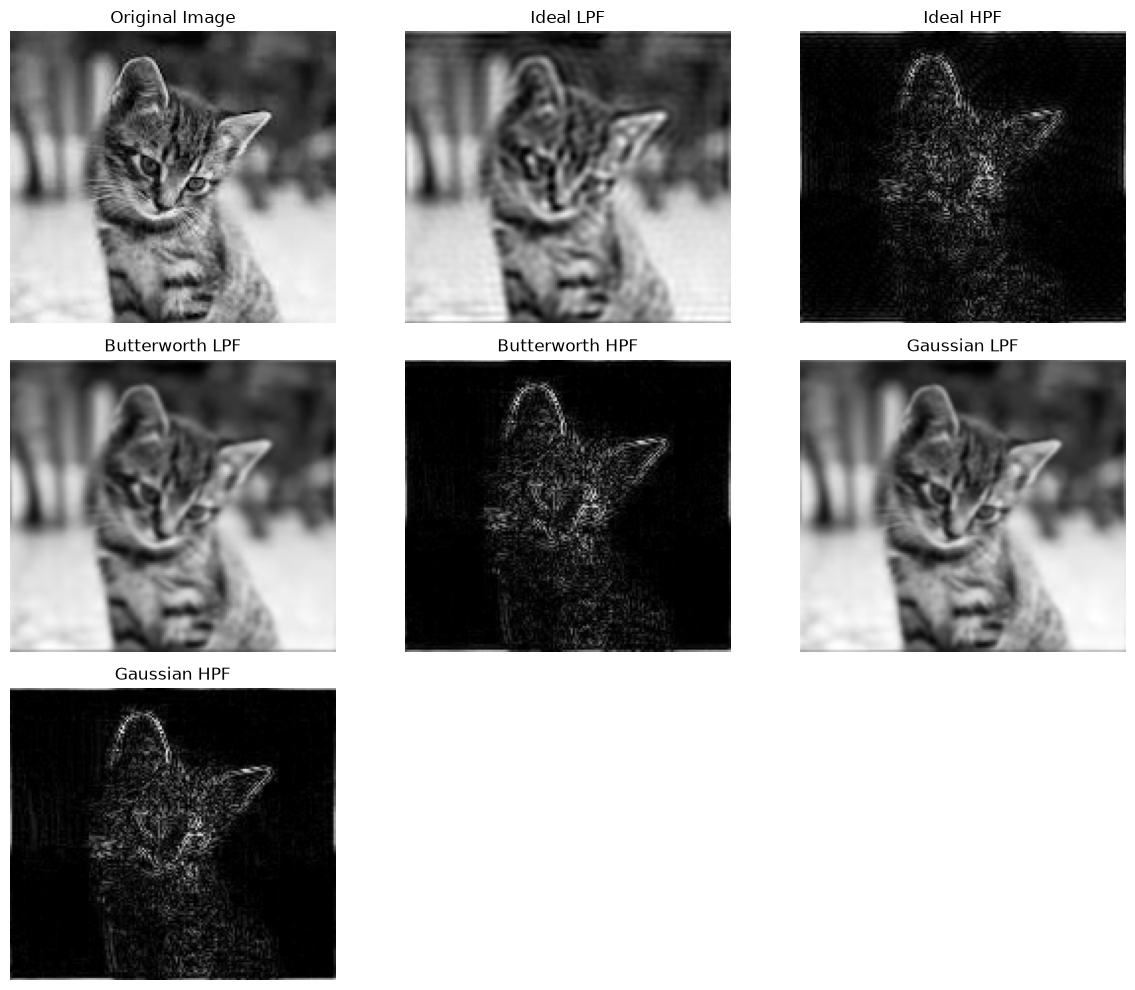

In [18]:
# Display results
images = [
    img, ideal_low, ideal_high,
    butter_low, butter_high,
    gaussian_low, gaussian_high
]

titles = [
    'Original Image',
    'Ideal LPF',
    'Ideal HPF',
    'Butterworth LPF',
    'Butterworth HPF',
    'Gaussian LPF',
    'Gaussian HPF'
]

plt.figure(figsize=(12, 10))

for i in range(7):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()